# GBT cross-check — LightGBM on the GNN inputs, no message passing (HI-Small)

- **Question:** do hand-crafted graph features (GFP) plus a tree model match the GNNs, or does message passing add something beyond them?
- **Inputs:** the same 93 columns the GNNs see — 81 edge features (20 baseline + 61 GFP V0, as stored in the graph files) + the 6 + 6 entity one-hots of the two endpoints. One feature set only (`full`).
- **Knobs:** none per run. Hyperparameters are chosen once by successive halving (Altman et al. 2023, Appendix C: x0 = 100, η = 2, r0 = 0.1) on the **train rows**, scored on **validation**; then four seeds (42–45) are trained with them.
- **Protocol:** the thesis protocol — validation scored every 25 boosting rounds, best-validation-F1 round kept with its threshold, test scored once, every metric on train / val / test. F1 at the paper's 0.5 threshold is stored alongside for comparison only.
- **Everything shared** (threshold sweep, metrics, loss diagnostic, curves, batch summary) comes from `gnn_core.py` through `gbt_core.py`; this notebook only sets the budget and the paths. Runs locally on CPU (not Kaggle); search trials and finished runs are skipped on rerun.

## 0. Environment (local)

- Conda env `graph_feature_preprocessor` (torch + PyG to read the graph files, LightGBM 4.6.0 for the trees; the paper used LightGBM 3.1.1).
- The repo root is the working directory, so the committed `gnn_core.py` / `gbt_core.py` are imported.

In [1]:
import os
import sys
import json

import lightgbm
import numpy as np
import pandas as pd

sys.path.insert(0, os.getcwd())
import gnn_core as core
import gbt_core

print(f'lightgbm {lightgbm.__version__} (paper: 3.1.1) | torch {core.torch.__version__} | threads {gbt_core.THREADS}')

lightgbm 4.6.0 (paper: 3.1.1) | torch 2.8.0+cpu | threads 16


C:\Users\User\.conda\envs\graph_feature_preprocessor\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

- The only settings cell: the halving budget, the seeds and the paths.
- `OUT_ROOT` mirrors `Outputs/GBT/` in the repo; the search log lives in `OUT_ROOT/search/`.

In [2]:
X0, ETA, R0  = gbt_core.X0, gbt_core.ETA, gbt_core.R0      # 100 configs -> 100 @ 10% -> 50 @ 20% -> 25 @ 40% -> 12 @ 80% -> 6 @ 100% of the train rows
SEEDS        = gbt_core.SEEDS                               # (42, 43, 44, 45); 42 is the run compared with the GNN runs
CHECK_EVERY  = gbt_core.CHECK_EVERY                         # validation checkpoint every 25 boosting rounds

DATA_DIR = 'Data'
OUT_ROOT = 'Outputs/GBT'
os.makedirs(f'{OUT_ROOT}/search', exist_ok=True)
print(f'halving schedule {gbt_core.halving_schedule(X0, ETA, R0)} | seeds {SEEDS} | out {OUT_ROOT}')

halving schedule [(100, 0.1), (50, 0.2), (25, 0.4), (12, 0.8), (6, 1.0)] | seeds (42, 43, 44, 45) | out Outputs/GBT


## 2. Load data

- One row per edge from the graph files: `edge_attr` (81) ‖ `x[src]` (6) ‖ `x[dst]` (6); labels of the train / val windows from their own snapshots.
- The split boundaries and the laundering counts per split must match `Progress_Report.md` §4 (asserted).

In [3]:
data = gbt_core.load_gbt_data(DATA_DIR)
print(data['cols'][:3], '...', data['cols'][-3:])

GBT matrix (5077237, 93) float32 (1.76 GB): 81 edge + 6 src + 6 dst columns
train rows         0 – 3,046,341  n=3,046,342  laundering=2,297 (0.0754%)
val   rows 3,046,342 – 4,061,788  n=1,015,447  laundering=1,082 (0.1066%)
test  rows 4,061,789 – 5,077,236  n=1,015,448  laundering=1,143 (0.1126%)
['Amount_Log', 'Struct_Band', 'Hour_Sin'] ... ['dst_EntityType_Individual', 'dst_EntityType_Partnership', 'dst_EntityType_Sole']


## 3. Hyperparameter search — successive halving on the train rows

- Each round fits every surviving config on the most recent fraction of the train rows and scores the full validation set (swept-threshold F1); the best half survives.
- `search/trials.csv` gets one line per (trial, round) as soon as it finishes; `search/best_params.json` holds the winner of the last round (full train rows).
- Test is not touched here.

In [4]:
best_params, trials = gbt_core.successive_halving(data, f'{OUT_ROOT}/search', X0, ETA, R0)
last_round = trials['round'].max()
trials[trials['round'] == last_round].sort_values('val_f1', ascending=False).head(10)

successive halving: x0=100 eta=2 r0=0.1 -> rounds [(100, 0.1), (50, 0.2), (25, 0.4), (12, 0.8), (6, 1.0)] | 2 trial rows already logged


--- round 1: 100 configs on the last 304,634 train rows (10%, 318 laundering) | 98 to fit


trial   2 | val F1 0.4540 @ 0.675 | PR-AUC 0.3801 | 84s | leaves 69 rounds 505 lr 0.036


trial   3 | val F1 0.3969 @ 0.728 | PR-AUC 0.3001 | 34s | leaves 122 rounds 157 lr 0.060


trial   4 | val F1 0.3504 @ 1.000 | PR-AUC 0.1632 | 86s | leaves 194 rounds 931 lr 0.093


...

trial  25 | val F1 0.5900 @ 0.286 | PR-AUC 0.5448 | 709s | leaves 192 rounds 567 lr 0.018


trial  52 | val F1 0.5882 @ 0.340 | PR-AUC 0.5471 | 215s | leaves 168 rounds 891 lr 0.013


trial   8 | val F1 0.5279 @ 0.292 | PR-AUC 0.3973 | 145s | leaves 176 rounds 496 lr 0.030


round 5 best: trial 73 val F1 0.5943 | median 0.5888 | 69.9 min
best configuration: trial 73 (validation F1 0.5943 on the full train rows)
{
 "num_round": 856,
 "num_leaves": 216,
 "learning_rate": 0.027150574733045343,
 "min_data_in_leaf": 383,
 "feature_fraction": 0.7346634670952006,
 "bagging_fraction": 0.5753364869066201,
 "lambda_l1": 0.034896346190664826,
 "lambda_l2": 5.263939224956252,
 "scale_pos_weight": 1.4018418007685098
}


,trial,round,fraction,n_rows,val_f1,threshold,val_pr_auc,seconds,params
187,73,5,1.0,3046342,0.594272,0.220498,0.544963,1051.360011,"{""num_round"": 856, ""num_leaves"": 216, ""learnin..."
190,25,5,1.0,3046342,0.589994,0.285708,0.544842,709.494504,"{""num_round"": 567, ""num_leaves"": 192, ""learnin..."
189,80,5,1.0,3046342,0.589424,0.281459,0.532987,1076.560321,"{""num_round"": 891, ""num_leaves"": 130, ""learnin..."
191,52,5,1.0,3046342,0.588235,0.339816,0.547090,215.474654,"{""num_round"": 891, ""num_leaves"": 168, ""learnin..."
188,1,5,1.0,3046342,0.577221,0.397066,0.527375,997.338309,"{""num_round"": 873, ""num_leaves"": 138, ""learnin..."
192,8,5,1.0,3046342,0.527859,0.291831,0.397337,144.659878,"{""num_round"": 496, ""num_leaves"": 176, ""learnin..."


## 4. Final runs — four seeds with the chosen configuration

- One call per seed: full train rows → validation checkpoint every 25 rounds → best round kept → all splits scored → `results.json`, `history.csv`, `curves.png`, `best.txt`, `predictions.csv` under `OUT_ROOT/<run>/`.
- `predictions.csv`: every edge of train / val / test with `edge_id`, `src`, `dst`, `edge_time`, `y`, `prob`, `pred` — same columns as the GNN runs.

=== lightgbm_readout-full_seed-42 ===
features: 93 | seed 42 | rounds 856 | checkpoint every 25


round   25 | loss 0.0224 / 0.0310 | F1 0.4621 / 0.5241 @ 0.051 | PR-AUC 0.4011 / 0.4573 | 13s   (train / val)   * new best


round   50 | loss 0.0184 / 0.0273 | F1 0.5040 / 0.5436 @ 0.103 | PR-AUC 0.4638 / 0.4828 | 5s   (train / val)   * new best


round   75 | loss 0.0160 / 0.0255 | F1 0.5230 / 0.5554 @ 0.164 | PR-AUC 0.5114 / 0.4953 | 7s   (train / val)   * new best


round  100 | loss 0.0142 / 0.0245 | F1 0.5457 / 0.5613 @ 0.198 | PR-AUC 0.5569 / 0.5078 | 8s   (train / val)   * new best


...

round  850 | loss 0.0015 / 0.0279 | F1 0.9950 / 0.5944 @ 0.229 | PR-AUC 0.9999 / 0.5449 | 74s   (train / val)


round  856 | loss 0.0015 / 0.0280 | F1 0.9946 / 0.5943 @ 0.220 | PR-AUC 0.9999 / 0.5450 | 72s   (train / val)


best validation F1 0.5949 at round 825 (threshold 0.229)


                    train     val    test
f1                 0.9944  0.5949  0.5219
precision          0.9905  0.8438  0.7451
recall             0.9983  0.4593  0.4016
pr_auc             0.9999  0.5448  0.4748
roc_auc            1.0000  0.9827  0.9805
precision_at_5pct  0.0151  0.0188  0.0195
recall_at_5pct     1.0000  0.8808  0.8644


predictions: 5,077,237 rows -> Outputs/GBT/lightgbm_readout-full_seed-42/predictions.csv


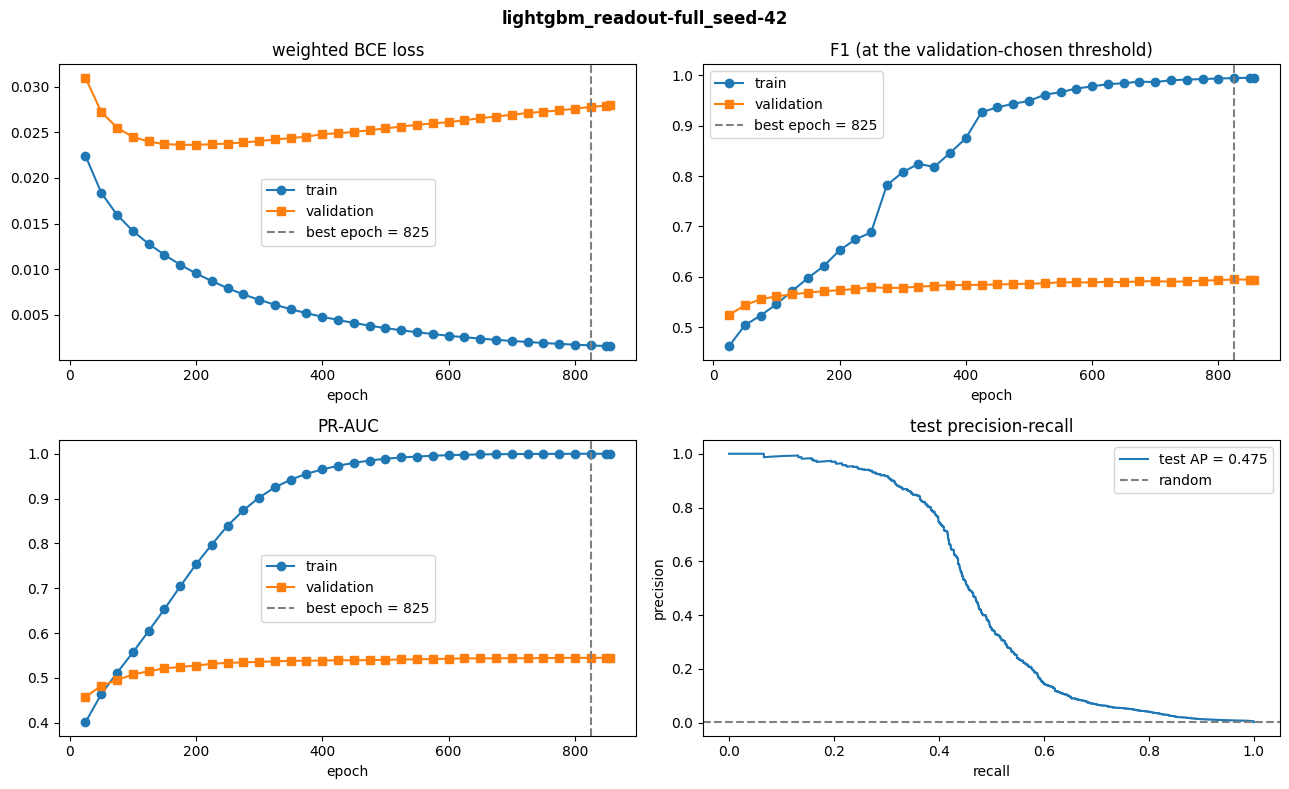

=== lightgbm_readout-full_seed-43 ===
features: 93 | seed 43 | rounds 856 | checkpoint every 25


round   25 | loss 0.0224 / 0.0308 | F1 0.4626 / 0.5229 @ 0.058 | PR-AUC 0.4006 / 0.4592 | 6s   (train / val)   * new best


round   50 | loss 0.0183 / 0.0271 | F1 0.5086 / 0.5394 @ 0.088 | PR-AUC 0.4665 / 0.4851 | 5s   (train / val)   * new best


round   75 | loss 0.0159 / 0.0254 | F1 0.5316 / 0.5532 @ 0.117 | PR-AUC 0.5130 / 0.4991 | 6s   (train / val)   * new best


round  100 | loss 0.0141 / 0.0244 | F1 0.5613 / 0.5597 @ 0.133 | PR-AUC 0.5610 / 0.5108 | 7s   (train / val)   * new best


...

round  850 | loss 0.0015 / 0.0279 | F1 0.9939 / 0.5873 @ 0.210 | PR-AUC 0.9999 / 0.5429 | 74s   (train / val)


round  856 | loss 0.0015 / 0.0279 | F1 0.9920 / 0.5869 @ 0.180 | PR-AUC 0.9999 / 0.5427 | 71s   (train / val)


best validation F1 0.5896 at round 725 (threshold 0.219)


                    train     val    test
f1                 0.9909  0.5896  0.5102
precision          0.9858  0.8291  0.6916
recall             0.9961  0.4575  0.4042
pr_auc             0.9995  0.5422  0.4677
roc_auc            1.0000  0.9825  0.9805
precision_at_5pct  0.0151  0.0188  0.0193
recall_at_5pct     1.0000  0.8808  0.8591


predictions: 5,077,237 rows -> Outputs/GBT/lightgbm_readout-full_seed-43/predictions.csv


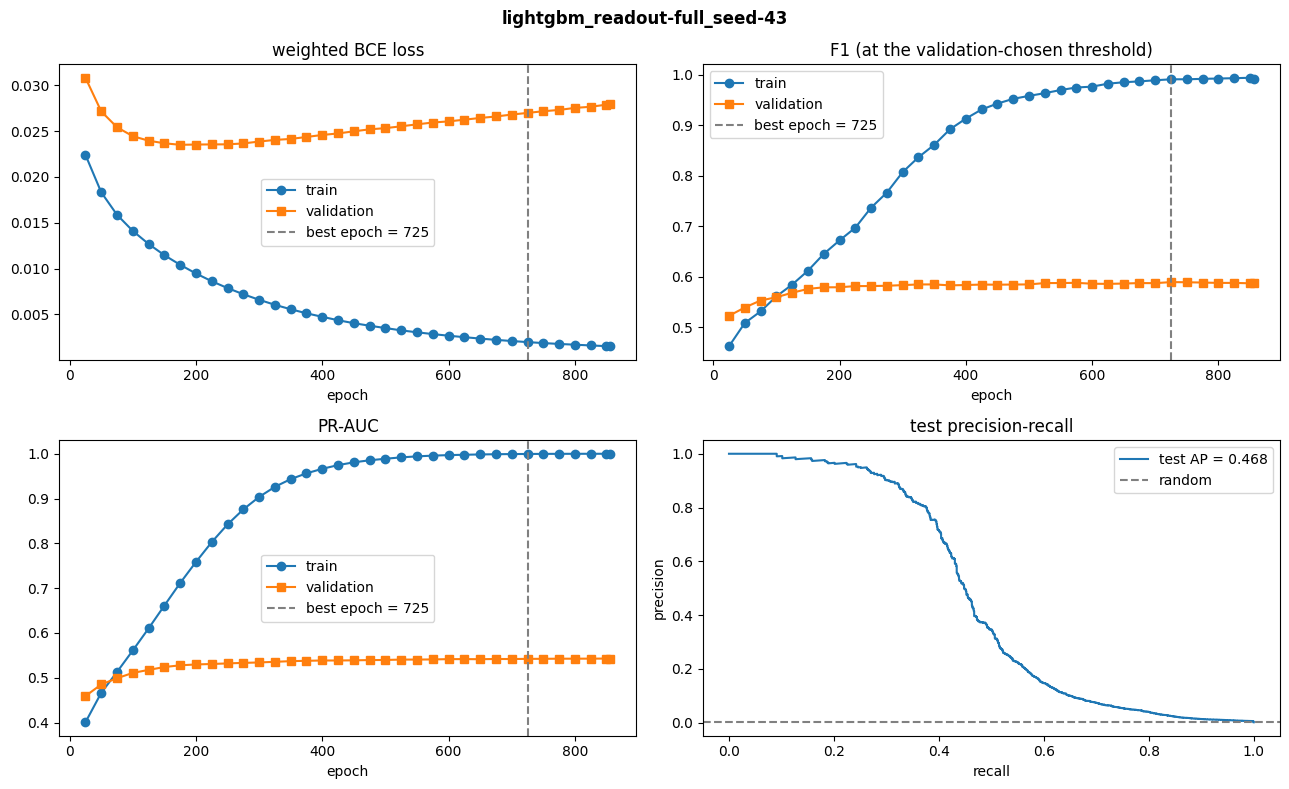

=== lightgbm_readout-full_seed-44 ===
features: 93 | seed 44 | rounds 856 | checkpoint every 25


round   25 | loss 0.0224 / 0.0309 | F1 0.4568 / 0.5136 @ 0.051 | PR-AUC 0.4020 / 0.4588 | 6s   (train / val)   * new best


round   50 | loss 0.0183 / 0.0270 | F1 0.5022 / 0.5427 @ 0.090 | PR-AUC 0.4636 / 0.4886 | 5s   (train / val)   * new best


round   75 | loss 0.0159 / 0.0254 | F1 0.5261 / 0.5533 @ 0.125 | PR-AUC 0.5110 / 0.5050 | 6s   (train / val)   * new best


round  100 | loss 0.0142 / 0.0246 | F1 0.5555 / 0.5608 @ 0.141 | PR-AUC 0.5586 / 0.5163 | 8s   (train / val)   * new best


...

round  850 | loss 0.0015 / 0.0279 | F1 0.9884 / 0.5906 @ 0.149 | PR-AUC 0.9999 / 0.5536 | 74s   (train / val)   * new best


round  856 | loss 0.0015 / 0.0279 | F1 0.9892 / 0.5903 @ 0.153 | PR-AUC 0.9999 / 0.5536 | 73s   (train / val)


best validation F1 0.5906 at round 850 (threshold 0.149)


                    train     val    test
f1                 0.9884  0.5906  0.5147
precision          0.9774  0.7779  0.6460
recall             0.9996  0.4760  0.4278
pr_auc             0.9999  0.5536  0.4774
roc_auc            1.0000  0.9827  0.9807
precision_at_5pct  0.0151  0.0188  0.0195
recall_at_5pct     1.0000  0.8808  0.8653


predictions: 5,077,237 rows -> Outputs/GBT/lightgbm_readout-full_seed-44/predictions.csv


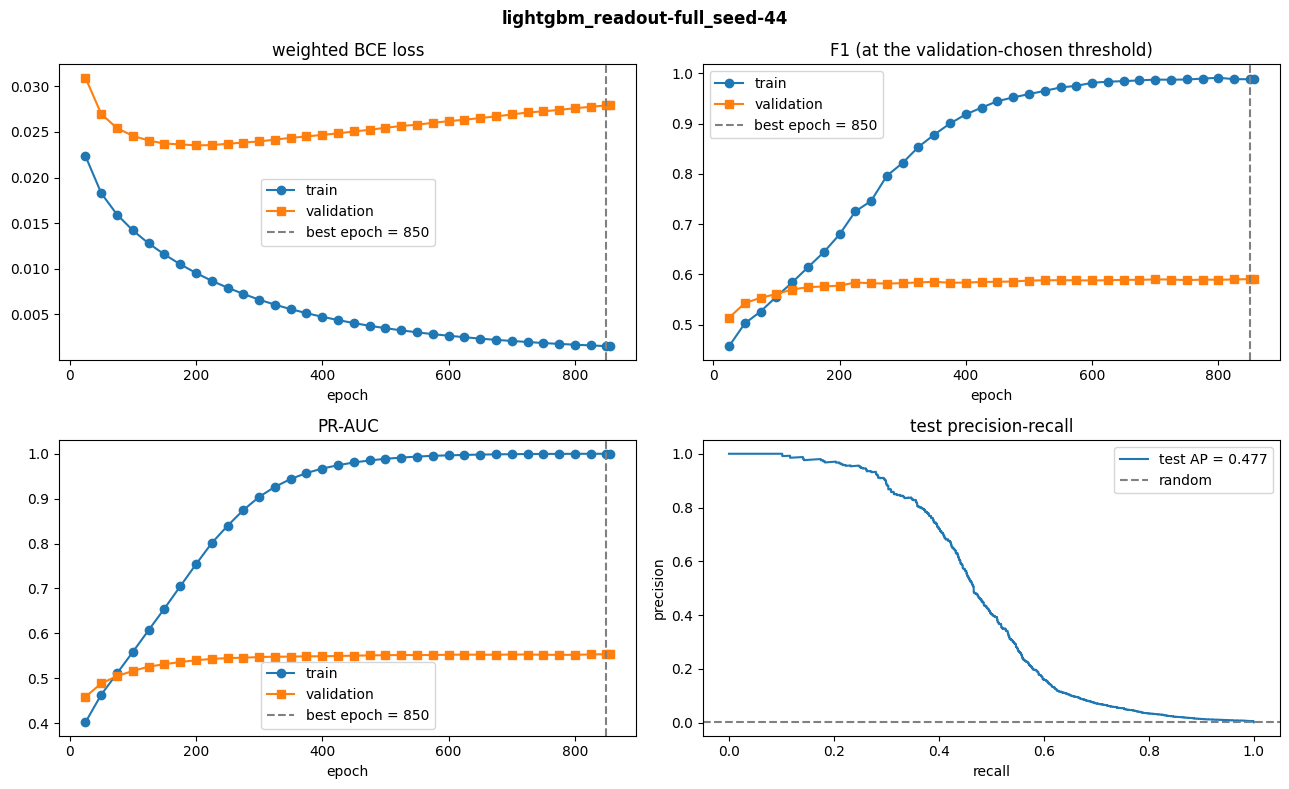

=== lightgbm_readout-full_seed-45 ===
features: 93 | seed 45 | rounds 856 | checkpoint every 25


round   25 | loss 0.0224 / 0.0317 | F1 0.4638 / 0.5292 @ 0.055 | PR-AUC 0.4083 / 0.4560 | 6s   (train / val)   * new best


round   50 | loss 0.0183 / 0.0275 | F1 0.5067 / 0.5488 @ 0.106 | PR-AUC 0.4665 / 0.4832 | 5s   (train / val)   * new best


round   75 | loss 0.0159 / 0.0257 | F1 0.5235 / 0.5569 @ 0.160 | PR-AUC 0.5154 / 0.4984 | 6s   (train / val)   * new best


round  100 | loss 0.0141 / 0.0247 | F1 0.5541 / 0.5647 @ 0.166 | PR-AUC 0.5630 / 0.5083 | 7s   (train / val)   * new best


...

round  850 | loss 0.0015 / 0.0280 | F1 0.9944 / 0.5919 @ 0.222 | PR-AUC 0.9999 / 0.5467 | 74s   (train / val)


round  856 | loss 0.0015 / 0.0281 | F1 0.9911 / 0.5918 @ 0.179 | PR-AUC 0.9999 / 0.5468 | 70s   (train / val)


best validation F1 0.5923 at round 625 (threshold 0.266)


                    train     val    test
f1                 0.9814  0.5923  0.5221
precision          0.9864  0.8694  0.7431
recall             0.9765  0.4492  0.4024
pr_auc             0.9976  0.5455  0.4751
roc_auc            1.0000  0.9827  0.9808
precision_at_5pct  0.0151  0.0188  0.0194
recall_at_5pct     1.0000  0.8817  0.8635


predictions: 5,077,237 rows -> Outputs/GBT/lightgbm_readout-full_seed-45/predictions.csv


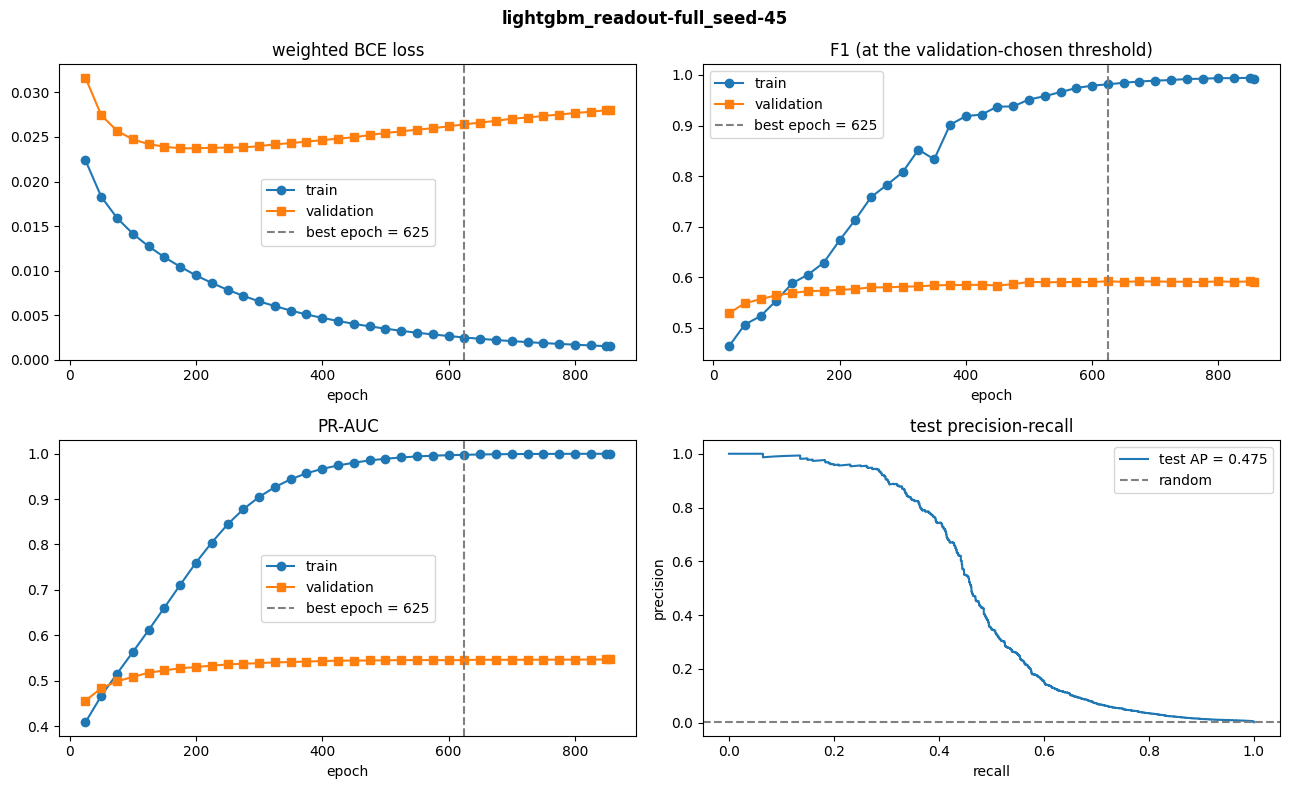

batch complete


In [5]:
rows = []
for seed in SEEDS:
    print('=' * 90)
    rows.append(gbt_core.train_final(best_params, data, seed, OUT_ROOT, CHECK_EVERY))
print('=' * 90)
print('batch complete')

## 5. Comparison across the seeds

- `batch_summary_gbt.csv` holds every `<split>_<metric>` column plus `threshold`, `best_epoch`, `params` (trees kept), `invariant_params` (0 by convention).
- `seed_summary_gbt.csv`: mean ± std over the four seeds. Only test F1 is a fair score here — validation picked the hyperparameters, the kept round and the threshold.

In [6]:
summary = core.summarize_batch(rows, OUT_ROOT, 'batch_summary_gbt.csv')
display(summary[core.DISPLAY_COLS].round(4))
seeds = gbt_core.seed_summary(rows, OUT_ROOT)
seeds[['n_seeds', 'val_f1_mean', 'val_f1_std', 'test_f1_mean', 'test_f1_std',
       'test_pr_auc_mean', 'test_pr_auc_std', 'best_epoch_mean']].round(4)

4 runs -> Outputs/GBT/batch_summary_gbt.csv | invariant_params = 0 in every row


,run,best_epoch,threshold,val_f1,test_f1,test_precision,test_recall,test_pr_auc,test_precision_at_5pct,test_recall_at_5pct,params,invariant_params
0,lightgbm_readout-full_seed-42,825,0.2289,0.5949,0.5219,0.7451,0.4016,0.4748,0.0195,0.8644,825,0
1,lightgbm_readout-full_seed-43,725,0.2189,0.5896,0.5102,0.6916,0.4042,0.4677,0.0193,0.8591,725,0
2,lightgbm_readout-full_seed-44,850,0.1487,0.5906,0.5147,0.6460,0.4278,0.4774,0.0195,0.8653,850,0
3,lightgbm_readout-full_seed-45,625,0.2657,0.5923,0.5221,0.7431,0.4024,0.4751,0.0194,0.8635,625,0


4 seeds -> Outputs/GBT/seed_summary_gbt.csv


,n_seeds,val_f1_mean,val_f1_std,test_f1_mean,test_f1_std,test_pr_auc_mean,test_pr_auc_std,best_epoch_mean
0,4,0.5919,0.0023,0.5172,0.0058,0.4738,0.0042,756.25
